---
title: "Understanding Deep Learning"
---

### II . Understanding Deep Learning

Having explored the historical background and inspiration behind deep learning, we can now delve into understanding the underlying mechanisms of this seemingly sci-fi technology. This journey will uncover how deep learning works, including the foundational concepts, methodologies, and real-world applications that make it a transformative force in modern technology.


#### Artificial Neural Network


Artificial Neural Networks (ANNs) consist of artificial neurons, known as **units**, organized into layers that form the entire network. These layers can range from having a few dozen units to millions, depending on the complexity required to learn hidden patterns in the data. Typically, an ANN includes an **input layer**, one or more **hidden layers**, and an **output layer**. The input layer receives external data for analysis, which is then processed through the hidden layers that transform the input into valuable information for the output layer. The output layer then generates a response based on the processed data.


*[Figure `figures/example1.png` belongs to the course handout and was not distributed with this notebook.]*


In most neural networks, units in different layers are interconnected, with each connection having a weight that determines the influence of one unit on another. As data flows through these connections, the neural network progressively learns from the data, ultimately producing an output from the output layer.

Artificial neural networks are trained using a dataset. To teach an ANN to recognize a cat, it is presented with thousands of different cat images. The network learns to identify cats by analyzing these images. Once trained, the ANN is tested by classifying new images and determining whether they are cat images or not. The output is compared to a human-provided label. If the ANN misclassifies an image, backpropagation is used to refine the network's weights based on the error rate. This process iterates until the ANN can accurately recognize cat images with minimal errors.


#### Feedforward Neural Network


The feedforward neural network is one of the most basic artificial neural networks. In this ANN, the data or the input provided travels in a single direction. It enters into the ANN through the input layer and exits through the output layer while hidden layers may or may not exist. So the feedforward neural network has a front-propagated wave only and usually does not have backpropagation.


Assume that the neurons have a **sigmoid** activation function, perform a forward pass on the network. Assume that the actual output of $y$ is 1 and **learning rate** $\alpha$ is 0.9.

To calculate $H_1$, we need to calculate first the weighted sum of the input values added by the bias $\theta$.

$$Z = \sum_j{(w_{i,j} \cdot x_i)} + \theta_i$$

$Z_1 = (w_{11} \cdot x_1) + (w_{13} \cdot x_2) + (w_{15} \cdot x_3) + \theta_1$

$Z_2 = (w_{12} \cdot x_1) + (w_{14} \cdot x_2) + (w_{16} \cdot x_3) + \theta_2$

After computing the **weighted sum**, we introduce non-linearity to the output result by applying a nonlinear function. For this example, let's use **sigmoid function**.

$$\sigma = \frac{1}{1+e^{-Z_i}}$$

$H_1 = \sigma(Z_1)$

$H_2 = \sigma(Z_2)$

Now that we have computed the hidden layer's value, we can now proceed to computing the weighted sum for the output layer using the same procedure as how we compute the $Z_n$ and $H_n$.

$Z_3 = (w_{21} \cdot H_1) + (w_{22} \cdot H_2) + \theta_3$

$\hat{y} = \sigma(Z_3)$

This is how the calculations in a feedforward neural network are traversed from input to output.


#### Laboratory Task 2

**Instruction:** Perform a single forward pass and compute for the error.

$$x = \begin{bmatrix} 1 \\ 0 \\ 1 \end{bmatrix}$$

$$y = \begin{bmatrix} 1 \end{bmatrix}$$

$$f=max(0, Z_n)$$

$$\text{hidden unit weights} =
\begin{bmatrix}
w_{11} = 0.2 && w_{12} = -0.3 \\
w_{13} = 0.4 && w_{14} = 0.1 \\
w_{15} = -0.5 && w_{16} = 0.2
\end{bmatrix}$$

$$\text{output unit weights} =
\begin{bmatrix}
w_{21} = -0.3 \\
w_{22} = -0.2
\end{bmatrix}$$

$$\theta =
\begin{bmatrix}
\theta_{1} = -0.4 \\
\theta_{2} = 0.2 \\
\theta_{3} = 0.1
\end{bmatrix}$$


### Laboratory Task 2 — Solution

**Forward pass with ReLU, $f(Z) = \max(0, Z)$.** Every unit takes the weighted sum of its
inputs, adds its bias, then passes the result through ReLU. The weight indices follow the
lesson: $w_{11}, w_{13}, w_{15}$ feed $H_1$ and $w_{12}, w_{14}, w_{16}$ feed $H_2$.

**Hidden unit 1**

$$Z_1 = w_{11}x_1 + w_{13}x_2 + w_{15}x_3 + \theta_1 = (0.2)(1) + (0.4)(0) + (-0.5)(1) + (-0.4) = -0.7$$

$$H_1 = \max(0,\,-0.7) = 0$$

**Hidden unit 2**

$$Z_2 = w_{12}x_1 + w_{14}x_2 + w_{16}x_3 + \theta_2 = (-0.3)(1) + (0.1)(0) + (0.2)(1) + 0.2 = 0.1$$

$$H_2 = \max(0,\,0.1) = 0.1$$

**Output unit**

$$Z_3 = w_{21}H_1 + w_{22}H_2 + \theta_3 = (-0.3)(0) + (-0.2)(0.1) + 0.1 = 0.08$$

$$\hat{y} = \max(0,\,0.08) = 0.08$$

**Error.** With the lesson's definition, $\delta = \hat{y} - y = 0.08 - 1 = -0.92$.
Written as a squared-error loss, $E = \tfrac{1}{2}(y - \hat{y})^2 = \tfrac{1}{2}(0.92)^2 = 0.4232$.

The network is far off: it predicts $0.08$ when the answer is $1$. Note that $Z_1$ is negative,
so ReLU switches $H_1$ off completely. Because ReLU's slope is $0$ for negative inputs, no
error signal will flow back through $H_1$ for this example, so $w_{11}, w_{13}, w_{15}, \theta_1$
and $w_{21}$ cannot change on the next update. Task 3 confirms this.

The cell below checks the hand computation with NumPy.

In [1]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)

x = np.array([1, 0, 1])
y = np.array([1])

# rows = inputs x1..x3, columns = hidden units H1, H2
W_h = np.array([[ 0.2, -0.3],    # w11, w12
                [ 0.4,  0.1],    # w13, w14
                [-0.5,  0.2]])   # w15, w16
b_h = np.array([-0.4, 0.2])      # theta1, theta2
W_o = np.array([[-0.3],          # w21
                [-0.2]])         # w22
b_o = np.array([0.1])            # theta3

relu = lambda z: np.maximum(0, z)

Z_h = x @ W_h + b_h
H = relu(Z_h)
Z_o = H @ W_o + b_o
y_hat = relu(Z_o)

print("Z1, Z2 =", Z_h, "  ->  H1, H2 =", H)
print("Z3     =", Z_o, "  ->  y_hat  =", y_hat)
print("delta = y_hat - y          =", y_hat - y)
print("E = 1/2 * (y - y_hat)^2    =", 0.5 * (y - y_hat) ** 2)

assert np.allclose(Z_h, [-0.7, 0.1]) and np.allclose(y_hat, [0.08])

Z1, Z2 = [-0.7  0.1]   ->  H1, H2 = [0.  0.1]
Z3     = [0.08]   ->  y_hat  = [0.08]
delta = y_hat - y          = [-0.92]
E = 1/2 * (y - y_hat)^2    = [0.4232]


#### Backward Propagation of Errors


Backward propagation a.k.a backprop or backward pass is a fundamental algorithm used for training artificial neural networks. It involves a two-step process: a forward pass and a backward pass. During the forward pass, input data is fed through the network, and the output is generated. The error, or the difference between the predicted output and the actual target, is then calculated. In the backward pass, this error is propagated back through the network, layer by layer, to update the weights and biases. This is done by computing the gradient of the loss function with respect to each weight using the chain rule of calculus. By iteratively adjusting the weights in the direction that reduces the error, backpropagation helps the network learn and improve its performance over time. This process continues until the network's predictions are sufficiently accurate or another stopping criterion is met.


The initial value for $\hat{y}$ is not the optimal value since the parameters used were just randomly selected. Therefore, after the forward propagation, a backward propagation algorithm is employed to update the parameters ($w$ and $\theta$).

The error at the output layer is calculated as the difference between the predicted output ($\hat{y}$) and the actual output ($y$):

$$\delta = \hat{y} - y$$

Compute Hidden Layer Error ($\delta_h$)

$$\delta_h = (\delta_o W^T_o) \cdot \sigma'(Z_h)$$

Where:

- $\sigma'(Z_h)$ is the derivative of the sigmoid activation function applied to the hidden layer activations $Z_h$:
- $\sigma'(Z_h) = A_h \cdot (1 - A_h)$
- $W^T_o$ is the transpose of the output weights matrix $W_o$.

Calculate Gradients

Once we have the errors ($\delta_o$ and $\delta_h$), we compute the gradients of the error with respect to the weights ($W_o$ and $W_h$).

Gradients for Output Layer Weights ($\frac{\partial E}{\partial W_o}$)

$$\frac{\partial E}{\partial W_o} = A\frac{T}{h} \delta_o$$

Gradients for Hidden Layer Weights ($\frac{\partial E }{\partial W_h}$)

$$\frac{\partial E}{\partial W_h} = X^T \delta_h$$

Finally, the weights are updated using the gradients and the learning rate ($\alpha$).


#### Laboratory Task 3

**Instruction:** Perform a forward and backward propagation in python using the inputs from **Laboratory Task 2**

```python
x = np.array([1, 0, 1])
y = np.array([1])

# use relu as the activation function.

# learning rate
lr = 0.001
```


### Laboratory Task 3 — Solution

The lesson derives backpropagation with a sigmoid. With ReLU only the activation derivative
changes: $f'(Z) = 1$ when $Z > 0$ and $0$ otherwise. Using the loss
$E = \tfrac{1}{2}(\hat{y} - y)^2$:

| Step | Formula |
|---|---|
| Output error | $\delta_o = (\hat{y} - y)\, f'(Z_3)$ |
| Output gradients | $\dfrac{\partial E}{\partial W_o} = H^T \delta_o, \quad \dfrac{\partial E}{\partial \theta_3} = \delta_o$ |
| Hidden error | $\delta_h = (\delta_o W_o^T) \odot f'(Z_h)$ |
| Hidden gradients | $\dfrac{\partial E}{\partial W_h} = x^T \delta_h, \quad \dfrac{\partial E}{\partial \theta_h} = \delta_h$ |
| Update | $W \leftarrow W - \alpha \dfrac{\partial E}{\partial W}$, with $\alpha = 0.001$ |

In [2]:
import numpy as np
np.set_printoptions(precision=6, suppress=True)

x = np.array([1, 0, 1])
y = np.array([1])

# use relu as the activation function.
def relu(z):
    return np.maximum(0, z)

def relu_grad(z):
    return (z > 0).astype(float)

# learning rate
lr = 0.001

# parameters from Laboratory Task 2
W_h = np.array([[ 0.2, -0.3],
                [ 0.4,  0.1],
                [-0.5,  0.2]])
b_h = np.array([-0.4, 0.2])
W_o = np.array([[-0.3],
                [-0.2]])
b_o = np.array([0.1])

def forward(x, W_h, b_h, W_o, b_o):
    Z_h = x @ W_h + b_h
    H = relu(Z_h)
    Z_o = H @ W_o + b_o
    return Z_h, H, Z_o, relu(Z_o)

# ---- forward pass ----
Z_h, H, Z_o, y_hat = forward(x, W_h, b_h, W_o, b_o)
loss = 0.5 * np.sum((y_hat - y) ** 2)
print(f"forward : H = {H}, y_hat = {y_hat}, loss = {loss:.6f}")

# ---- backward pass ----
delta_o = (y_hat - y) * relu_grad(Z_o)          # (1,)
dW_o = np.outer(H, delta_o)                     # H^T delta_o -> (2, 1)
db_o = delta_o

delta_h = (delta_o @ W_o.T) * relu_grad(Z_h)    # (2,)
dW_h = np.outer(x, delta_h)                     # x^T delta_h -> (3, 2)
db_h = delta_h

print("delta_o =", delta_o, "  delta_h =", delta_h)
print("dE/dW_o =\n", dW_o, "\ndE/db_o =", db_o)
print("dE/dW_h =\n", dW_h, "\ndE/db_h =", db_h)

# ---- gradient-descent update ----
W_o_new = W_o - lr * dW_o
b_o_new = b_o - lr * db_o
W_h_new = W_h - lr * dW_h
b_h_new = b_h - lr * db_h

print("\nupdated W_h =\n", W_h_new, "\nupdated b_h =", b_h_new)
print("updated W_o =\n", W_o_new, "\nupdated b_o =", b_o_new)

# ---- forward again with the updated parameters ----
_, _, _, y_hat_new = forward(x, W_h_new, b_h_new, W_o_new, b_o_new)
loss_new = 0.5 * np.sum((y_hat_new - y) ** 2)
print(f"\nafter one step: y_hat = {y_hat_new}, loss = {loss_new:.6f} (was {loss:.6f})")
assert loss_new < loss

forward : H = [0.  0.1], y_hat = [0.08], loss = 0.423200
delta_o = [-0.92]   delta_h = [0.    0.184]
dE/dW_o =
 [[-0.   ]
 [-0.092]] 
dE/db_o = [-0.92]
dE/dW_h =
 [[0.    0.184]
 [0.    0.   ]
 [0.    0.184]] 
dE/db_h = [0.    0.184]

updated W_h =
 [[ 0.2      -0.300184]
 [ 0.4       0.1     ]
 [-0.5       0.199816]] 
updated b_h = [-0.4       0.199816]
updated W_o =
 [[-0.3     ]
 [-0.199908]] 
updated b_o = [0.10092]

after one step: y_hat = [0.08104], loss = 0.422244 (was 0.423200)


**Cross-check with PyTorch autograd.** The same network written in PyTorch lets
`loss.backward()` compute the gradients. If the hand-derived NumPy gradients are right, the two
must match.

In [3]:
import torch

xt = torch.tensor(x, dtype=torch.float64)
yt = torch.tensor(y, dtype=torch.float64)
Wh = torch.tensor(W_h, requires_grad=True)
bh = torch.tensor(b_h, requires_grad=True)
Wo = torch.tensor(W_o, requires_grad=True)
bo = torch.tensor(b_o, requires_grad=True)

out = torch.relu(torch.relu(xt @ Wh + bh) @ Wo + bo)
torch_loss = 0.5 * ((out - yt) ** 2).sum()
torch_loss.backward()

for name, mine, auto in [("W_h", dW_h, Wh.grad), ("b_h", db_h, bh.grad),
                         ("W_o", dW_o, Wo.grad), ("b_o", db_o, bo.grad)]:
    assert np.allclose(mine, auto.numpy()), name
    print(f"{name}: NumPy and autograd gradients match")

W_h: NumPy and autograd gradients match
b_h: NumPy and autograd gradients match
W_o: NumPy and autograd gradients match
b_o: NumPy and autograd gradients match


**What the numbers say.**

- The output error is $\delta_o = -0.92$: the prediction is too low, so every update pushes $\hat{y}$ upward.
- $\delta_h = [0,\ 0.184]$. The first entry is exactly zero because $H_1$ was switched off by ReLU
  ($Z_1 = -0.7 < 0$). As Task 2 predicted, the first column of $\partial E / \partial W_h$, $\theta_1$
  and $w_{21}$ get zero gradient and are unchanged.
- $x_2 = 0$, so the second row of $\partial E / \partial W_h$ is zero too. A weight attached to an
  input of zero cannot be blamed for the error.
- With $\alpha = 0.001$ the step is tiny. The loss only moves from $0.4232$ to about $0.4222$.
  Many more iterations, or a larger learning rate, would be needed to bring $\hat{y}$ close to $1$.

#### Introduction to PyTorch


:::{image} https://upload.wikimedia.org/wikipedia/commons/9/96/Pytorch_logo.png
:alt: PyTorch logo
:width: 15%
:align: center
:::

PyTorch is a powerful and widely-used open-source framework for deep learning, developed by Facebook's AI Research lab. It is designed to provide flexibility and speed for both research and production environments. PyTorch's primary strength lies in its dynamic computation graph, which allows for real-time changes and debugging, making it easier to experiment with new ideas. This is in contrast to static computation graphs used by other frameworks like TensorFlow. PyTorch supports a range of applications, from natural language processing to computer vision, through its extensive library of pre-built modules and tools. Additionally, its integration with Python makes it accessible to a large community of developers and researchers, fostering rapid development and collaboration. With a strong emphasis on simplicity and performance, PyTorch has become a go-to tool for many in the deep learning community.

**Setting up the Virtual Enviroment**


A virtual environment is a self-contained directory that isolates a specific Python environment, allowing users to manage dependencies and packages for different projects independently. This ensures that each project can have its own unique set of libraries and versions without conflicts, avoiding issues that arise from global installations. Virtual environments are particularly useful for maintaining consistent development environments, making it easier to manage project-specific dependencies and ensuring that applications run smoothly across different setups. Tools like **venv** and **virtualenv** facilitate the creation and management of these environments. We can create a virtual environment using either **pip** or **conda**.


1. **With pip**
   - Make sure that you have installed Python and have its directory path added in the machine's environment variables.
   - Create a new folder, make sure that you know the directory of the new folder that you have created.
   - Open command prompt and change the directory to the new folder that you created.
   - Considering that you already have configured pip in the environment variables, you can now install libraries.
   - Run command `pip install virtualenv`.
   - You can create a virtual environment with a specific Python version but only if the specific version is installed in your system.
   - Run command `virtualenv -p /path/to/pythonX.X /path/to/new/virtual/environment`
   - Replace `/path/to/pythonX.X` with the path to the desired Python executable (e.g., `/usr/bin/python3.8`) and `/path/to/new/virtual/environment` with the path where you want to create the virtual environment.
   - Activate the virtual environment, make sure that you are inside the directory where the environment's folder is also under.
   - Run command `env_name/Scripts/activate`.
   - Replace `env_name` with the name of the environment you created.
2. **With conda**
   - Make sure that [Anaconda](https://www.anaconda.com/) is installed in your system.
   - Open Anaconda prompt and run command `conda create -n <myenv> python=3.X`
   - Activate the environment by running the command `conda activate env_name`.
   - Replace `env_name` with the name of the environment you created.

**PyTorch Installation**


1. Make sure that python is installed in your local device, the stable version of pytorch runs on python version 3.6 to 3.9. Make sure that your python version is in between this range. You can check the python version using command the command;
2. Activate the virtual environment, for this demonstration, let's just use the conda virtual enviroment.
3. Go to [https://pytorch.org/get-started/locally/](https://pytorch.org/get-started/locally/) and select appropriate machine configurations and copy the generated command.

If you have a CUDA enabled GPU, you can download and install CUDA toolkit version 11.8 or 12.1 first. Otherwise you may only select CPU.
4. Paste the command in the anaconda prompt where you activated the virtual enviroment and wait patiently.

Just click `Y` when prompted with a question to proceed installation.


#### PyTorch Components

Let's have linear regression as a case study to study the different components of PyTorch.  These are the following components we will be covering:

1. Specifying input and target
2. Dataset and DataLoader
3. `nn.Linear` (Dense)
4. Define loss function
5. Define optimizer function
6. Train the model


Consider this data:

*[Figure `figures/japan.png` belongs to the course handout and was not distributed with this notebook.]*

In a linear regression model, each target variable is estimated to be a weighted sum of the input variables, offset by some constant, known as a bias :

$$\text{yield}_\text{apple}  = w_{11} \cdot \text{temp} + w_{12} \cdot \text{rainfall} + w_{13} \cdot \text{humidity} + b_{1}$$

$$\text{yield}_\text{orange} = w_{21} \cdot \text{temp} + w_{22} \cdot \text{rainfall} + w_{23} \cdot \text{humidity} + b_{2}$$

Visually, it means that the yield of apples is a linear or planar function of temperature, rainfall and humidity:

*[Figure `figures/japan2.png` belongs to the course handout and was not distributed with this notebook.]*

The learning part of linear regression is to figure out a set of weights **w11, w12,... w23, b1 & b2** using gradient descent.


**Sample Implementation**


In [4]:
import torch
import numpy as np
import sys

In [5]:
torch.__version__

'2.7.1+cu118'

In [6]:
#We can check whether we have gpu
device = torch.device("cuda:0" if (torch.cuda.is_available()) else "cpu")
print("Device: ", device)

Device:  cuda:0


**1. Specifiying input and target**


In [7]:
# Input (temp, rainfall, humidity)
x_train = np.array([
    [73, 67, 43], [91, 88, 64], [87, 134, 58], 
    [102, 43, 37], [69, 96, 70], [73, 67, 43], 
    [91, 88, 64], [87, 134, 58], [102, 43, 37], 
    [69, 96, 70], [73, 67, 43], [91, 88, 64], 
    [87, 134, 58], [102, 43, 37], [69, 96, 70]], 
                   dtype='float32')

# Targets (apples, oranges)
y_train = np.array([
    [56, 70], [81, 101], [119, 133], 
    [22, 37], [103, 119], [56, 70], 
    [81, 101], [119, 133], [22, 37], 
    [103, 119], [56, 70], [81, 101], 
    [119, 133], [22, 37], [103, 119]], 
                   dtype='float32')

In [8]:
inputs = torch.from_numpy(x_train)
targets = torch.from_numpy(y_train)
print(inputs.size())
print(targets.size())

torch.Size([15, 3])
torch.Size([15, 2])


**2. Dataset and DataLoader**

PyTorch provides two data primitives: [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) and [`torch.utils.data.Dataset`](https://pytorch.org/vision/0.18/datasets.html) that allow you to use pre-loaded datasets as well as your own data. Dataset stores the samples and their corresponding labels, and DataLoader wraps an iterable around the Dataset to enable easy access to the samples.


In [9]:
from torch.utils.data import TensorDataset

In [10]:
# Define dataset
train_ds = TensorDataset(inputs, targets)
train_ds[0:3]

(tensor([[ 73.,  67.,  43.],
         [ 91.,  88.,  64.],
         [ 87., 134.,  58.]]),
 tensor([[ 56.,  70.],
         [ 81., 101.],
         [119., 133.]]))

We'll now create a `DataLoader`, which can split the data into batches of a predefined size while training. It also provides other utilities like shuffling and random sampling of the data.


In [11]:
from torch.utils.data import DataLoader

In [12]:
# Define data loader
batch_size = 3
train_dl = DataLoader(train_ds, batch_size, shuffle=True)


In [13]:
x, y = next(iter(train_dl))

The `DataLoader` is typically used in a for-in loop. Let's look at an example


In [14]:
for xb, yb in train_dl:
    print(xb)
    print(yb)
    break

tensor([[ 69.,  96.,  70.],
        [ 87., 134.,  58.],
        [ 69.,  96.,  70.]])
tensor([[103., 119.],
        [119., 133.],
        [103., 119.]])


In each iteration, the data loader returns one batch of data, with the given batch size. If shuffle is set to True, it shuffles the training data before creating batches. Shuffling helps randomize the input to the optimization algorithm, which can lead to faster reduction in the loss.


**3. Define some Layer - `nn.Linear`**

Instead of initializing the weights & biases manually, we can define the model using the `nn.Linear` class from PyTorch, which does it automatically.


In [15]:
import torch.nn as nn
import random
import os

def seed_everything(seed=42):
  random.seed(seed)
  os.environ['PYTHONHASHSEED'] = str(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

In [16]:
# Define model

seed_everything()
model = nn.Linear(3, 2)  #nn.Linear assume this shape (in_features, out_features)
print(model.weight)
print(model.weight.size()) # (out_features, in_features)
print(model.bias)
print(model.bias.size()) #(out_features)

Parameter containing:
tensor([[ 0.4414,  0.4792, -0.1353],
        [ 0.5304, -0.1265,  0.1165]], requires_grad=True)
torch.Size([2, 3])
Parameter containing:
tensor([-0.2811,  0.3391], requires_grad=True)
torch.Size([2])


In fact, our model is simply a function that performs a matrix multiplication of the `inputs` and the weights `w` and adds the bias `b` (for each observation)

*[Figure `figures/dot.png` belongs to the course handout and was not distributed with this notebook.]*

PyTorch models also have a helpful `.parameters` method, which returns a list containing all the weights and bias matrices present in the model. For our linear regression model, we have one weight matrix and one bias matrix.


In [17]:
# Parameters
list(model.parameters())  #model.param returns a generator

[Parameter containing:
 tensor([[ 0.4414,  0.4792, -0.1353],
         [ 0.5304, -0.1265,  0.1165]], requires_grad=True),
 Parameter containing:
 tensor([-0.2811,  0.3391], requires_grad=True)]

In [18]:
#we can print the complexity by the number of parameters
print(sum(p.numel() for p in model.parameters() if p.requires_grad))

8


We can use the `model(tensor)` API to perform a forward-pass that generate predictions.


In [19]:
# Generate predictions
preds = model(inputs)
preds

tensor([[58.2323, 35.5896],
        [73.4005, 44.9262],
        [94.4899, 36.2867],
        [60.3437, 53.3070],
        [66.7117, 32.9453],
        [58.2323, 35.5896],
        [73.4005, 44.9262],
        [94.4899, 36.2867],
        [60.3437, 53.3070],
        [66.7117, 32.9453],
        [58.2323, 35.5896],
        [73.4005, 44.9262],
        [94.4899, 36.2867],
        [60.3437, 53.3070],
        [66.7117, 32.9453]], grad_fn=<AddmmBackward0>)

**4. Define Loss Function**

The `nn` module contains a lot of useful loss function like this:


In [20]:
criterion_mse = nn.MSELoss()
criterion_softmax_cross_entropy_loss = nn.CrossEntropyLoss()

In [21]:
mse = criterion_mse(preds, targets)
print(mse)
print(mse.item())  ##print out the loss number

tensor(2480.3708, grad_fn=<MseLossBackward0>)
2480.370849609375


**5. Define the Optimizer**

We use  `optim.SGD` to perform stochastic gradient descent where samples are selected in batches (often with random shuffling) instead of as a single group.  Note that  `model.parameters()` is passed as an argument to `optim.SGD`.


In [22]:
# Define optimizer
#momentum update the weight based on past gradients also, which will be useful for getting out of local max/min
#If our momentum parameter was $0.9$, we would get our current grad + the multiplication of the gradient 
#from one time step ago by $0.9$, the one from two time steps ago by $0.9^2 = 0.81$, etc.

opt = torch.optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

**6. Training - Putting Everything Together**


In [23]:
# Utility function to train the model
def fit(num_epochs, model, loss_fn, opt, train_dl):
    
    # Repeat for given number of epochs
    for epoch in range(num_epochs):
        
        # Train with batches of data
        for xb,yb in train_dl:
            
            xb.to(device) #move them to gpu if possible, if not, it will be cpu
            yb.to(device)
                    
            # 1. Predict
            pred = model(xb)
                      
            # 2. Calculate loss
            loss = loss_fn(pred, yb)
            
            # 3. Calculate gradient
            opt.zero_grad()  #if not, the gradients will accumulate
            loss.backward()
            
            # Print out the gradients.
            # print ('dL/dw: ', model.weight.grad) 
            # print ('dL/db: ', model.bias.grad)
            
            # 4. Update parameters using gradients
            opt.step()
            
        # Print the progress
        if (epoch+1) % 10 == 0:
            sys.stdout.write("\rEpoch [{}/{}], Loss: {:.4f}".format(epoch+1, num_epochs, loss.item()))

In [24]:
#train for 100 epochs
fit(100, model, criterion_mse, opt, train_dl)

Epoch [70/100], Loss: 17.3556

Epoch [100/100], Loss: 16.4972

In [25]:
# Generate predictions
preds = model(inputs)
loss = criterion_mse(preds, targets)
print(loss.item())

2.9683969020843506


In [26]:
preds

tensor([[ 56.4532,  71.0035],
        [ 81.6630, 101.5495],
        [120.7658, 134.5193],
        [ 17.4769,  37.0754],
        [103.0401, 120.3559],
        [ 56.4532,  71.0035],
        [ 81.6630, 101.5495],
        [120.7658, 134.5193],
        [ 17.4769,  37.0754],
        [103.0401, 120.3559],
        [ 56.4532,  71.0035],
        [ 81.6630, 101.5495],
        [120.7658, 134.5193],
        [ 17.4769,  37.0754],
        [103.0401, 120.3559]], grad_fn=<AddmmBackward0>)

In [27]:
targets

tensor([[ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.],
        [ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.],
        [ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.]])

#### Laboratory Task 4

**Instruction:** Train a linear regression model in PyTorch using a regression dataset. Use the following parameters.

- Criterion: MSE Loss
- Fully Connected Layers x 2
- Batch Size: 8
- Optimizer: SGD
- Epoch: 1000


### Laboratory Task 4 — Solution

**Dataset.** scikit-learn's *Diabetes* regression dataset (442 patients, 10 baseline
measurements such as age, BMI, blood pressure and six blood serum values). The target is a
quantitative measure of disease progression one year later. It ships with scikit-learn, so
no download is needed.

**Setup.** 80/20 train/validation split (`random_state=42`). Inputs and target are
standardised with statistics from the training split only. The model has the two fully connected
layers required, with a ReLU between them. Without the ReLU the two layers would collapse into a
single linear map, $W_2(W_1x + b_1) + b_2 = Wx + b$, which is plain linear regression.

| Setting | Value |
|---|---|
| Criterion | `nn.MSELoss()` |
| Layers | `Linear(10, 16) → ReLU → Linear(16, 1)` |
| Batch size | 8 |
| Optimizer | `torch.optim.SGD`, lr = 0.01 |
| Epochs | 1000 |

In [28]:
import time
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

seed_everything(42)

X, y = load_diabetes(return_X_y=True)
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=42)

x_scaler, y_scaler = StandardScaler().fit(X_tr), StandardScaler().fit(y_tr.reshape(-1, 1))
to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr_t, Xva_t = to_t(x_scaler.transform(X_tr)), to_t(x_scaler.transform(X_va))
ytr_t = to_t(y_scaler.transform(y_tr.reshape(-1, 1)))
yva_t = to_t(y_scaler.transform(y_va.reshape(-1, 1)))

train_dl_diab = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=8, shuffle=True)
print(f"train: {tuple(Xtr_t.shape)}   validation: {tuple(Xva_t.shape)}   "
      f"batches/epoch: {len(train_dl_diab)}")

train: (353, 10)   validation: (89, 10)   batches/epoch: 45


In [29]:
# The model is tiny (193 parameters), so the CPU is faster than shuttling batches to a GPU.
reg_device = torch.device("cpu")

reg_model = nn.Sequential(
    nn.Linear(10, 16),   # fully connected layer 1
    nn.ReLU(),
    nn.Linear(16, 1),    # fully connected layer 2
).to(reg_device)
print(reg_model)
print("trainable parameters:", sum(p.numel() for p in reg_model.parameters()))

reg_loss_fn = nn.MSELoss()
reg_opt = torch.optim.SGD(reg_model.parameters(), lr=0.01)


def fit_regression(num_epochs, model, loss_fn, opt, train_dl, X_val, y_val):
    history = {"train": [], "val": []}
    for epoch in range(num_epochs):
        model.train()
        running, n = 0.0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(reg_device), yb.to(reg_device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.item() * len(xb)
            n += len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val.to(reg_device)), y_val.to(reg_device)).item()
        history["train"].append(running / n)
        history["val"].append(val_loss)
        if (epoch + 1) % 100 == 0:
            print(f"Epoch [{epoch + 1:4d}/{num_epochs}]  train MSE: {running / n:.4f}  "
                  f"val MSE: {val_loss:.4f}  (standardised units)")
    return history


t0 = time.perf_counter()
history = fit_regression(1000, reg_model, reg_loss_fn, reg_opt, train_dl_diab, Xva_t, yva_t)
print(f"training time: {time.perf_counter() - t0:.1f} s")

Sequential(
  (0): Linear(in_features=10, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
trainable parameters: 193


Epoch [ 100/1000]  train MSE: 0.4000  val MSE: 0.4393  (standardised units)


Epoch [ 200/1000]  train MSE: 0.3400  val MSE: 0.4586  (standardised units)


Epoch [ 300/1000]  train MSE: 0.2959  val MSE: 0.5298  (standardised units)


Epoch [ 400/1000]  train MSE: 0.2861  val MSE: 0.4723  (standardised units)


Epoch [ 500/1000]  train MSE: 0.2707  val MSE: 0.5307  (standardised units)


Epoch [ 600/1000]  train MSE: 0.2560  val MSE: 0.6872  (standardised units)


Epoch [ 700/1000]  train MSE: 0.2408  val MSE: 0.5669  (standardised units)


Epoch [ 800/1000]  train MSE: 0.2278  val MSE: 0.5978  (standardised units)


Epoch [ 900/1000]  train MSE: 0.2266  val MSE: 0.6814  (standardised units)


Epoch [1000/1000]  train MSE: 0.2725  val MSE: 0.5948  (standardised units)
training time: 27.3 s


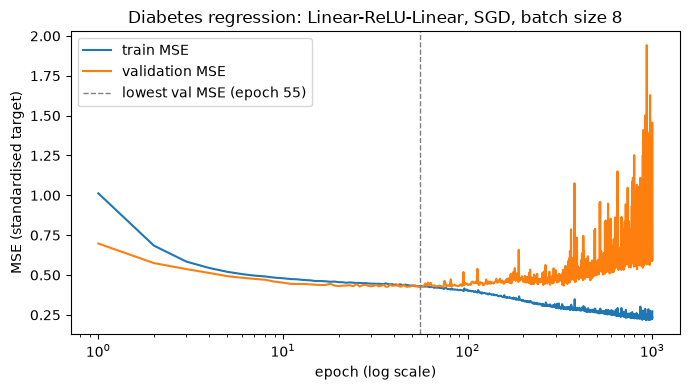

In [30]:
best_epoch = int(np.argmin(history["val"])) + 1

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 1001), history["train"], label="train MSE")
ax.plot(range(1, 1001), history["val"], label="validation MSE")
ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"lowest val MSE (epoch {best_epoch})")
ax.set_xscale("log")
ax.set_xlabel("epoch (log scale)")
ax.set_ylabel("MSE (standardised target)")
ax.set_title("Diabetes regression: Linear-ReLU-Linear, SGD, batch size 8")
ax.legend()
plt.tight_layout()
plt.show()

In [31]:
# Report in the target's original units, next to two reference points:
#   * a baseline that always predicts the training mean
#   * closed-form ordinary least squares (true linear regression)
reg_model.eval()
with torch.no_grad():
    pred_va = y_scaler.inverse_transform(reg_model(Xva_t).numpy()).ravel()

ols = LinearRegression().fit(x_scaler.transform(X_tr), y_tr)
pred_ols = ols.predict(x_scaler.transform(X_va))
pred_mean = np.full_like(y_va, y_tr.mean())

print(f"{'model':<34}{'val MSE':>10}{'val RMSE':>10}{'val R2':>8}")
for name, p in [("predict training mean", pred_mean),
                ("OLS linear regression (sklearn)", pred_ols),
                ("2-layer net, SGD, 1000 epochs", pred_va)]:
    print(f"{name:<34}{mean_squared_error(y_va, p):>10.1f}"
          f"{mean_squared_error(y_va, p) ** 0.5:>10.1f}{r2_score(y_va, p):>8.3f}")
to_orig = y_scaler.scale_[0] ** 2   # standardised MSE -> original units
print(f"\nnet, final epoch : val MSE {history['val'][-1]:.4f} standardised = "
      f"{history['val'][-1] * to_orig:.1f} original units")
print(f"net, best epoch  : val MSE {min(history['val']):.4f} standardised = "
      f"{min(history['val']) * to_orig:.1f} original units (epoch {best_epoch})")
print(f"train MSE        : {history['train'][0]:.4f} at epoch 1 -> {history['train'][-1]:.4f} at epoch 1000")

model                                val MSE  val RMSE  val R2
predict training mean                 5361.5      73.2  -0.012
OLS linear regression (sklearn)       2900.2      53.9   0.453
2-layer net, SGD, 1000 epochs         3613.9      60.1   0.318

net, final epoch : val MSE 0.5948 standardised = 3613.9 original units
net, best epoch  : val MSE 0.4232 standardised = 2571.8 original units (epoch 55)
train MSE        : 1.0126 at epoch 1 -> 0.2725 at epoch 1000


**Interpretation.**

- **Training keeps improving, but validation does not.** Training MSE drops from 1.01 in epoch 1
  to about 0.23–0.27 near the end, with some SGD jitter. Validation MSE reaches its lowest point
  (0.42) at epoch 55 and is about 0.59 by epoch 1000. From then on the extra epochs mostly fit noise in the 353 training rows. That is
  overfitting, visible as the widening gap between the two curves.
- **After 1000 epochs, the network loses to plain linear regression.** Its validation R² is 0.318
  against 0.453 for OLS, and both beat the predict-the-mean baseline (R² ≈ 0). At its best epoch
  the network scored *better* than OLS on validation. That figure is optimistic, though: the
  epoch was picked by looking at those same validation rows, so a fair test would need a third,
  untouched split.
- **The validation curve is jumpy.** With a batch size of 8, every SGD step uses a very noisy
  gradient estimate, and with only 89 validation rows a few predictions can swing the MSE.
- **Practical takeaway.** On a small, mostly linear tabular dataset, the 1000-epoch budget is far
  more than needed. Early stopping on a validation split, or regularisation such as weight decay,
  matters more here than the extra layer.